# 02 · Weekly panel

**What this notebook does.** It turns the daily files from notebook 01 into **one weekly table**, `data/processed/weekly_panel.csv`: **one row per Friday, Jan 7, 2005 → Nov 6, 2026 (1,140 weeks)**. Every later notebook reads only this table. No internet is needed.

**How a week works.** A week runs **Saturday → Friday** and is named after its Friday, so weekend news lands in the week when markets can react. Each row holds what was known at that Friday's close; nothing is lagged here.

### The columns, one by one

**Brent spot price (FRED, daily closes)**

| Column | Meaning |
|---|---|
| `price` | Brent price at the week's last trading day (usually Friday), in USD |
| `r` | Weekly return in %: how much the price went up or down since last Friday. Computed as 100 × ln(price / last week's price). The regime-switching model is fitted on this. |
| `rv` | Weekly **realized variance**: how much the price bounced around *during* the week. Sum of the squared daily returns. Big = turbulent week. |
| `log_rv` | The natural log of `rv`. Same information, but crisis spikes become moderate bumps. Used as "last week's volatility" in the model. |
| `n_days` | Number of trading days in the week (fewer in holiday weeks) |

**Hourly Brent (Dukascopy), from Jun 7, 2013; empty before**

| Column | Meaning |
|---|---|
| `rv_hourly` | Realized variance from **hourly** returns (~105 per week instead of 5), so a much more precise `rv`. **The main yardstick forecasts are scored against.** |
| `log_rv_hourly` | The natural log of `rv_hourly` |
| `n_hours_week` | Number of hourly returns in the week (normal ≈ 105) |
| `rv_gk` | A third variance measure from each day's open/high/low/close (Garman–Klass). Appendix only. |

**Iran news (GDELT)**

| Column | Meaning |
|---|---|
| `iran_share` | Share of all news articles that week that are about Iran (e.g. 0.02 = 2%) |
| `iran_gdelt` | The natural log of `iran_share`. **The main Iran-news variable in the models.** |
| `iran_gdelt_geo` | Same, but also counting events that happen *in* Iran (robustness check) |
| `iran_conflict` | Log share of articles about Iran **conflict** (threats, attacks) |
| `iran_coop` | Log share of articles about Iran **cooperation** (talks, deals) |
| `iran_tone` | Average tone of Iran articles (negative = more hostile wording) |
| `iran_goldstein` | Average Goldstein score of Iran events (−10 = war-like, +10 = cooperative) |
| `gdelt_days` | Days with GDELT data in the week (normal = 7) |
| `gdelt_filled` | 1 for the one week without any GDELT data (Jun 27, 2025; previous week copied), else 0 |

**Other risk measures**

| Column | Meaning |
|---|---|
| `gpr` | Log of the global geopolitical risk index (weekly average) |
| `vix` | Log of the VIX, US stock-market fear index (Friday close) |
| `ovx` | Log of the OVX, oil-market fear index (Friday close; starts May 2007) |
| `aigpr_iran` | Log of the monthly Iran geopolitical risk index, using the latest month already published by that Friday |

**Decisions from notebook 01 applied here:**
- GDELT: archive before Apr 1, 2013, daily feed after; "stale" rows counted as normal news; Jun 14, 2025 filled from GDELT 2.0; the empty week ending Jun 27, 2025 copies the previous week (`gdelt_filled = 1`).
- Hourly RV starts Jun 7, 2013.

**Outputs:** `weekly_panel.csv` (committed), `results/tables/{data_summary, rv_measures_check}.csv`, and five figures in `results/figures/`.


## 0 · Setup

In [1]:
# ── SETUP ──────────────────────────────────────────────────────────────────────────────
# Reload src/brent/*.py automatically when we edit them.
%load_ext autoreload
%autoreload 2

import numpy as np                             # maths on arrays (logs, correlations, ...)
import pandas as pd                            # tables with dates
import matplotlib.pyplot as plt                # plotting
import statsmodels.api as sm                   # regressions (OLS) for the Apr 2013 break check
from statsmodels.tsa.stattools import adfuller # the ADF unit-root test for the data table

import brent
from brent import config as C      # every constant and decision
from brent import paths            # file locations + size budget
from brent import plots            # figure style + save_fig (150 dpi PNG)
from brent import sources as S     # load_raw: reads the frozen data/raw/*.csv
from brent import weekly as W      # all week logic (tested in tests/test_weekly.py)

np.random.seed(C.SEED)
plots.setup_style()                # inline figures at 100 dpi
pd.set_option("display.width", 160)

# Notebook 02 always rebuilds the panel (it takes a second and needs no network), so there is no
# skip logic here. Nothing below downloads anything.
# The nine Iran event dates from config.py, each moved to the Friday that ends its week
# (e.g. Abqaiq, Sat Sep 14, 2019 -> Fri Sep 20, 2019). Used to mark the events on the plots.
EVENT_WEEKS = {e[0]: W.week_ending(pd.Timestamp(e[1])) for e in C.EVENTS}   # the nine Iran event weeks

## 1 · Load the frozen raw files

`brent_intraday_daily.csv` is local only (git-ignored, decided in notebook 01). On a fresh clone, run notebook 01's section 5 first; the cell below stops with that message if the file is missing.

In [2]:
# ── LOAD THE FROZEN RAW FILES (written by notebook 01) ─────────────────────────────────
# key used in this notebook -> file name in data/raw/ (without ".csv")
RAW_FILES = {"brent": "brent_daily", "vix": "vix_daily", "ovx": "ovx_daily", "gpr": "gpr_daily",
             "aigpr": "aigpr_iran_monthly", "gdelt": "gdelt_daily", "gdelt_v2": "gdelt_v2_2025_daily",
             "intraday": "brent_intraday_daily"}
# Stop early with a clear message if a file is missing (on a fresh clone: the Dukascopy file is local only).
missing = [f for f in RAW_FILES.values() if not (paths.RAW / f"{f}.csv").exists()]
if missing:
    raise FileNotFoundError(f"missing raw files: {missing}. brent_intraday_daily is local only: run notebook 01, "
                            "section 5 (needs `uv sync --group intraday`), then rerun this notebook.")

# Read every file into a dict: raw["brent"] is the Brent table, raw["gdelt"] the GDELT table, etc.
raw = {key: S.load_raw(name) for key, name in RAW_FILES.items()}
# Quick overview: rows and date range per file (AI-GPR is monthly, so its date column is "month").
for key, df in raw.items():
    dcol = "month" if key == "aigpr" else "date"
    print(f"{key:9s} {len(df):6,} rows  {df[dcol].min().date()} -> {df[dcol].max().date()}")

brent      9,125 rows  1987-05-20 -> 2026-11-06
vix        5,552 rows  2004-12-01 -> 2026-11-06
ovx        4,908 rows  2007-05-10 -> 2026-11-06
gpr        8,011 rows  2004-12-01 -> 2026-11-06
aigpr        274 rows  2004-01-01 -> 2026-10-01
gdelt     12,822 rows  2005-01-01 -> 2026-11-06
gdelt_v2     696 rows  2025-01-01 -> 2025-12-31
intraday   4,058 rows  2010-12-02 -> 2026-11-06


## 2 · Build the panel

`W.build_weekly_panel` does all the work (spec §9.1). It **stops with an error** if any week has no Brent trading day, zero Iran articles in any measure, an AI-GPR value ≤ 0, or (from Jun 7, 2013) no hourly return. Nothing is filled silently. The one exception is GDELT's single empty week, decided in notebook 01.

In [3]:
# ── BUILD THE WEEKLY PANEL ─────────────────────────────────────────────────────────────
# One call does everything (see src/brent/weekly.py): map each daily row to its Friday week, then
#   Brent  -> price, r (weekly return), rv (sum of squared daily returns), n_days
#   GDELT  -> Iran share = sum of Iran articles / sum of all articles, conflict/coop shares, tone, Goldstein
#   GPR / VIX / OVX / AI-GPR -> weekly mean or Friday value; Dukascopy -> rv_hourly, rv_gk
# It STOPS with an error if a week has no Brent trading day, zero Iran articles, etc. (nothing is filled).
panel = W.build_weekly_panel(raw)
counts = panel.attrs["gdelt_counts"]          # what happened to the GDELT rows (stored on the table)
print(f"panel: {len(panel):,} weeks, {panel['date'].min().date()} -> {panel['date'].max().date()}, "
      f"{panel.shape[1]} columns\n")

# What happened to the GDELT rows on the way:
#  - wrong side: archive rows dated after Apr 1, 2013 (or daily rows before it) are dropped
#  - stale: rows GDELT dated > 1 year before adding them; counted as normal news (the Jan 2020 glitch)
#  - patched / carried forward: the Jun 2025 outage (1 day filled from GDELT 2.0, 1 week copied)
print(f"GDELT rows dropped for being on the wrong side of the Apr 1, 2013 switch: {counts['wrong_side']}")
print(f"'stale' rows merged into the daily feed: {counts['stale_rows']:,} rows, {counts['stale_events']:,} events")
print(f"outage days filled from GDELT 2.0: {counts['patched_days']}; empty weeks carried forward: {counts['filled_weeks']}")

# Where the stale events are (expect Jan 2020, the broken-event-date days):
g = raw["gdelt"]
stale = g[g["feed"] == "stale"]
# Sum the stale events per week and show the 5 weeks with the most.
top_stale = stale.groupby(W.week_ending(stale["date"]).to_numpy())["n_events"].sum().nlargest(5)
print("\nweeks holding the most stale events (all merged, i.e. counted as normal news):")
display(top_stale.to_frame("stale events"))

panel: 1,140 weeks, 2005-01-07 -> 2026-11-06, 23 columns

GDELT rows dropped for being on the wrong side of the Apr 1, 2013 switch: 2
'stale' rows merged into the daily feed: 4,897 rows, 669,444 events
outage days filled from GDELT 2.0: 1; empty weeks carried forward: 1

weeks holding the most stale events (all merged, i.e. counted as normal news):


,stale events
2020-01-03,362448
2020-01-10,174217
2017-03-24,443
2017-04-07,402
2024-09-06,402


**Stale events:** January 2020 holds 80% of them (536,665 of 669,444, in the weeks ending Jan 3 and Jan 10), as we expected from notebook 01.
- They are the Soleimani-strike coverage, which GDELT stamped with a broken event date.
- Counting them as normal news is right: that spike in Iran news was real.
- Every other week has at most a few hundred, which is negligible.

### GDELT 2.0 patch: calibration table

The patch needs GDELT 2.0 to move with 1.0 on the 2025 weeks both cover fully. For each series: `shift` is how far 2.0 sits from 1.0 (log points for shares, levels for tone/Goldstein), `corr` is the weekly correlation, and `pass` means corr ≥ 0.8. Only the main Iran share (`articles_iran_actor`) *must* pass; for the others a low correlation is reported, not fatal.

overlap weeks: 47; volume ratio 1.0/2.0 (all articles): 1.317


,shift,corr,weight_ratio,n_weeks,pass
articles_iran_actor,-0.104,0.932,NaN,47,True
articles_iran_actor_geo,-0.207,0.930,NaN,47,True
articles_iran_conflict,-0.143,0.882,NaN,47,True
articles_iran_coop,-0.095,0.947,NaN,47,True
iran_tone,-0.555,0.816,1.314,47,True
iran_goldstein,0.127,0.788,1.314,47,False


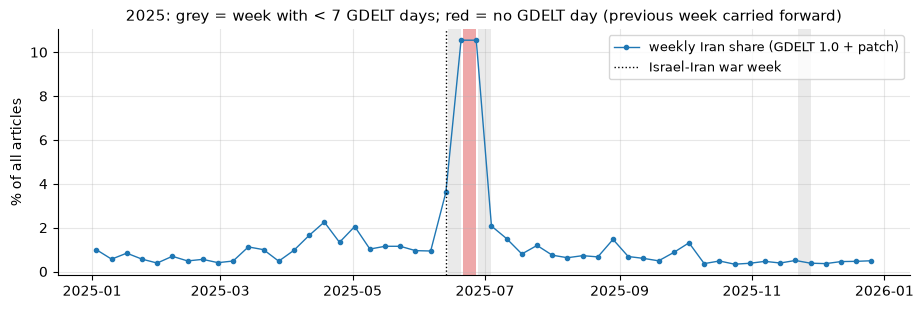

In [4]:
# ── GDELT 2.0 PATCH: the calibration table and the 2025 picture ────────────────────────
# GDELT 1.0 (our source) went down Jun 14 - Jul 1, 2025. GDELT 2.0 counts news differently, so before
# borrowing its numbers we compare the two on the 2025 weeks BOTH covered fully ("overlap weeks"):
#   shift  = how far 2.0 usually sits from 1.0 -> used to convert 2.0's numbers to 1.0's scale
#   corr   = do the two move together week by week? (1 = perfectly in step)
#   pass   = corr >= 0.8; only the main Iran share (articles_iran_actor) MUST pass
#   weight_ratio (tone/Goldstein) = how many more Iran articles 1.0 counts than 2.0
patch_info = W.v2_patch_info(raw["gdelt"], raw["gdelt_v2"])
# "vol" = how many more articles in total 1.0 counts than 2.0 (1.317 = 32% more).
print(f"overlap weeks: {int(patch_info['n_weeks'].iloc[0])}; volume ratio 1.0/2.0 (all articles): "
      f"{patch_info.attrs['vol']:.3f}")
display(patch_info.round(3))

# 2025 weekly Iran share around the outage: patched week (1 day from 2.0) and the carried-forward week.
p25 = panel.set_index("date").loc["2025-01-01":"2025-12-31"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(p25.index, 100 * p25["iran_share"], marker=".", lw=1, label="weekly Iran share (GDELT 1.0 + patch)")
# Shade every week that is missing GDELT days: grey = some days missing, red = no day at all (copied week).
for d, row in p25[(p25["gdelt_days"] < 7)].iterrows():
    color = "tab:red" if row["gdelt_filled"] else "0.8"
    ax.axvspan(d - pd.Timedelta(days=6), d, color=color, alpha=0.4, lw=0)   # Saturday..Friday of that week
ax.axvline(EVENT_WEEKS["israel_iran_2025"], color="k", ls=":", lw=1, label="Israel-Iran war week")
ax.set_ylabel("% of all articles")
ax.set_title("2025: grey = week with < 7 GDELT days; red = no GDELT day (previous week carried forward)")
ax.legend(loc="upper right"); plt.show()

The problem here is that GDELT 2.0 was down on the exact same days as GDELT 1.0 (Jun 15 – Jul 1, 2025), except for the first day of the 1.0 outage (Jun 14), so it doesn't help our case much.
- The calibration itself is fine: the main Iran share correlates 0.93 between the two versions (pass). Only Goldstein (0.79) is just under 0.8, which is reported, not fatal.
- Result (see section 6): the week ending Jun 20 rests on 1 day, the week ending Jun 27 copies it (`gdelt_filled = 1`), and the week ending Jul 4 has 3 days.
- So the Israel–Iran war weeks of 2025 are measured roughly. The event study should mention this.

In [5]:
# ── SAVE THE PANEL (the input of every later notebook) ─────────────────────────────────
# Save the panel: the input of every later notebook. Dates as YYYY-MM-DD.
paths.PROCESSED.mkdir(parents=True, exist_ok=True)            # make data/processed/ if it doesn't exist
panel.to_csv(paths.PROCESSED / "weekly_panel.csv", index=False, date_format="%Y-%m-%d")
print(f"saved weekly_panel.csv ({(paths.PROCESSED / 'weekly_panel.csv').stat().st_size / 1e3:.0f} KB)")
display(panel.tail(3))                                        # the last three weeks, as a sanity look

saved weekly_panel.csv (371 KB)


,date,price,r,rv,log_rv,n_days,iran_share,iran_gdelt,iran_gdelt_geo,gdelt_days,...,ovx,aigpr_iran,iran_conflict,iran_coop,iran_tone,iran_goldstein,rv_hourly,log_rv_hourly,n_hours_week,rv_gk
1137,2026-10-23,128.30,7.247851,62.019599,4.127450,5,0.016976,-4.075981,-3.758980,7,...,4.094678,4.118463,-5.167431,-4.485047,-3.529928,0.049021,34.365035,3.537040,105.0,35.627053
1138,2026-10-30,120.15,-6.563031,54.662774,4.001183,5,0.020507,-3.886982,-3.546452,7,...,4.068685,4.118463,-4.973031,-4.298788,-3.090962,-0.011328,41.061275,3.715065,105.0,36.951272
1139,2026-11-06,97.83,-20.550968,402.079162,5.996649,5,0.029129,-3.536009,-3.218540,7,...,4.065431,4.262809,-4.661020,-3.928532,-3.229748,0.199340,75.552723,4.324831,105.0,79.910152


## 3 · Data table

Per variable (missing weeks dropped): N, mean, SD, min, max, the AR(1) coefficient (how persistent it is), and an ADF unit-root test (constant, lag length by AIC). A small ADF p-value means the series looks stationary, which the regime-switching models assume for their regressors.

In [6]:
# ── DATA TABLE: summary statistics for every variable (saved to results/tables/) ───────
SUMMARY_COLS = ["r", "rv", "log_rv", "rv_hourly", "log_rv_hourly", "rv_gk", "iran_gdelt", "iran_conflict",
                "iran_coop", "iran_tone", "iran_goldstein", "gpr", "vix", "ovx", "aigpr_iran"]
rows = []
for col in SUMMARY_COLS:
    x = panel[col].dropna()                    # drop empty weeks (e.g. hourly RV before Jun 2013)
    # ADF test: is the series "stationary" (fluctuates around a fixed mean)? Small p-value (< 0.05) = yes.
    # A large p-value means it drifts like a random walk, which matters for how it can enter a model.
    adf_stat, adf_p, *_ = adfuller(x, regression="c", autolag="AIC", result_object=False)
    rows.append({"variable": col, "N": len(x), "mean": x.mean(), "sd": x.std(), "min": x.min(), "max": x.max(),
                 # AR(1) = correlation with last week's value: near 1 = very persistent, near 0 = no memory.
                 "ar1": x.autocorr(1), "adf_stat": adf_stat, "adf_p": adf_p})
data_summary = pd.DataFrame(rows)
paths.save_table(data_summary.round(4), "data_summary")       # -> results/tables/data_summary.csv
data_summary.round(3)

,variable,N,mean,sd,min,max,ar1,adf_stat,adf_p
0,r,1140,0.078,5.376,-34.639,29.446,0.101,-16.846,0.000
1,rv,1140,35.851,198.855,0.109,6115.116,0.127,-11.025,0.000
2,log_rv,1140,2.677,1.152,-2.216,8.719,0.509,-5.925,0.000
3,rv_hourly,701,29.604,66.409,1.413,969.391,0.469,-7.107,0.000
4,log_rv_hourly,701,2.814,0.940,0.346,6.877,0.790,-4.544,0.000
5,rv_gk,701,31.556,83.501,1.108,1310.391,0.409,-7.623,0.000
6,iran_gdelt,1140,-4.204,0.669,-5.880,-1.669,0.783,-5.487,0.000
7,iran_conflict,1140,-5.334,0.711,-7.033,-2.286,0.736,-6.392,0.000
8,iran_coop,1140,-4.621,0.680,-6.260,-2.404,0.790,-5.074,0.000
9,iran_tone,1140,0.222,4.266,-7.305,6.688,0.986,-1.266,0.645


`adf_p` = p-value of the Augmented Dickey–Fuller test, which tests whether a series is stationary (keeps returning to a stable average) or not. Below 0.05 = stationary.
- All series pass except `iran_tone` (p = 0.645).
- The reason is visible in Figure 4: tone has two permanent level jumps (Nov 2012 and Feb 2015). So tone can't be used in levels in the models.
- `ar1` shows how persistent a series is: VIX, OVX and AI-GPR Iran (0.91–0.94) change slowly; weekly returns (0.10) have almost no memory.

## 4 · Figures

### Figure 1: every series over time

- One small chart per variable, with a dashed line where the 2026 holdout starts (first week of 2026).

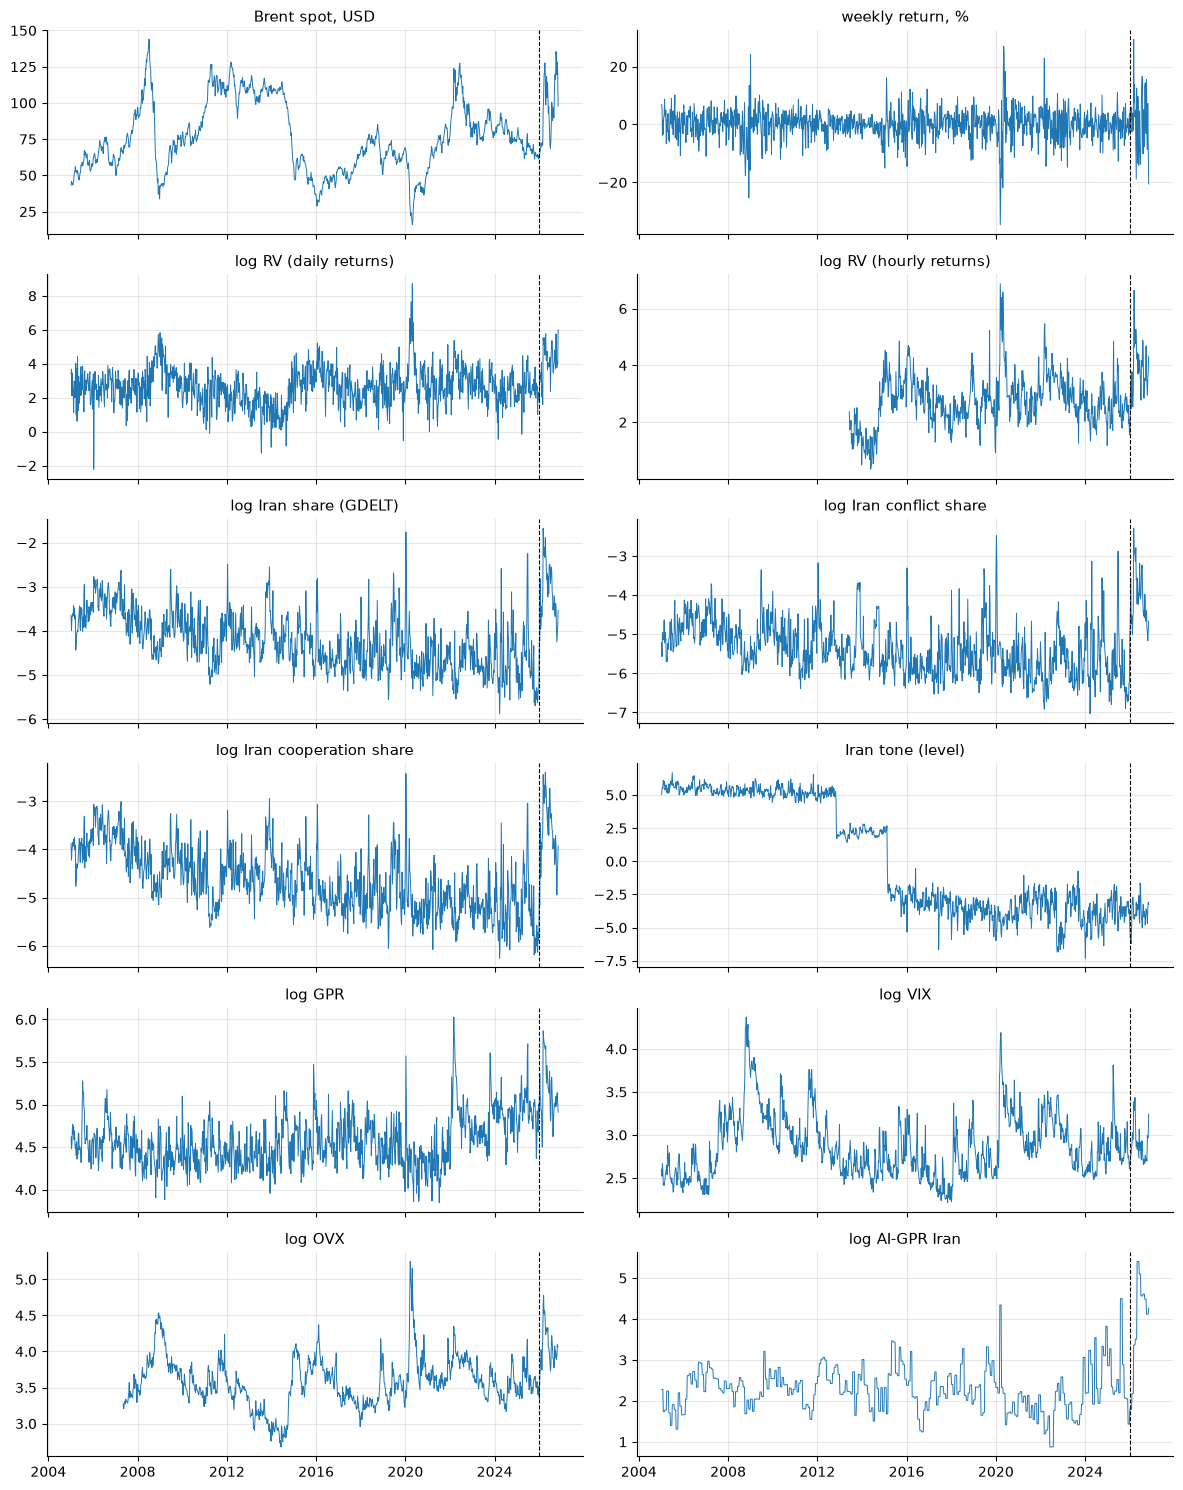

In [7]:
SERIES = [("price", "Brent spot, USD"), ("r", "weekly return, %"), ("log_rv", "log RV (daily returns)"),
          ("log_rv_hourly", "log RV (hourly returns)"), ("iran_gdelt", "log Iran share (GDELT)"),
          ("iran_conflict", "log Iran conflict share"), ("iran_coop", "log Iran cooperation share"),
          ("iran_tone", "Iran tone (level)"), ("gpr", "log GPR"), ("vix", "log VIX"), ("ovx", "log OVX"),
          ("aigpr_iran", "log AI-GPR Iran")]
fig, axes = plt.subplots(6, 2, figsize=(12, 15), sharex=True)   
for ax, (col, label) in zip(axes.flat, SERIES):                 
    ax.plot(panel["date"], panel[col], lw=0.7)
    ax.axvline(pd.Timestamp("2026-01-01"), color="k", ls="--", lw=0.8)   
    ax.set_title(label)
fig.tight_layout()
plots.save_fig(fig, "data_series"); plt.show()

Insights:

- The 2026 holdout is an extreme Iran period: Brent up to $135, the Iran news share and AI-GPR Iran at their highest levels in the sample, and high volatility. A tough but useful out-of-sample test.
- Volatility (log RV) comes in clusters: calm stretches, then spikes in 2008, 2014–16, 2020 (COVID) and 2026.
- Hourly RV starts in Jun 2013, OVX in May 2007.
- Iran tone moves in permanent steps (see Figure 4).

### Figure 2 + Check: Does the Iran share jump at the 2013 GDELT switch?

- Before April 2013 GDELT's numbers come from its archive: 1979–2005 one file per year, 2006 – Mar 2013 one file per month. From Apr 1, 2013 on: the daily news feed.
- If the two count differently, the Iran share could jump at the switch, which is an artefact, not news.
- Saved to gdelt_share_2013_break.png

mean log Iran share, 52 weeks before: -4.160   after: -3.910   (difference +0.250)
OLS on the whole sample, iran_gdelt ~ 1 + post2013 (descriptive only): coef -0.538, t = -14.3


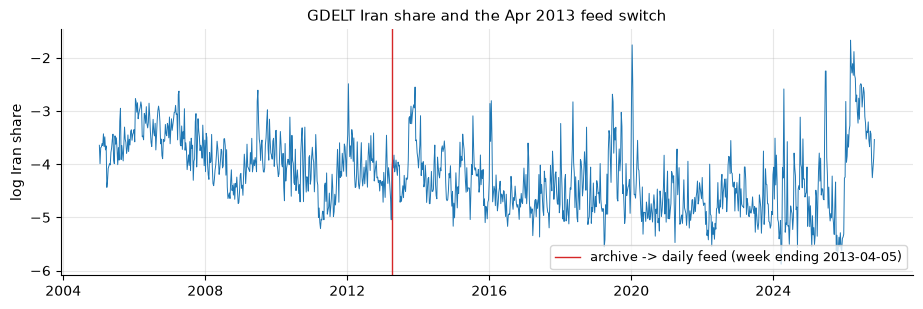

In [8]:
SWITCH_WEEK = pd.Timestamp(C.DUMMY_POST2013_WEEK)          # first week fully on the daily-feed side, April 1st 2013
s = panel.set_index("date")["iran_gdelt"]
# Compare the year just before with the year just after the switch.
before = s[s.index < SWITCH_WEEK].tail(52); after = s[s.index >= SWITCH_WEEK].head(52)
# A simple regression on a 0/1 "after the switch" dummy over the whole sample 
# (descriptive only: it also picks up the long-run trend, e.g. the 2005-2012 nuclear-crisis years with lots of Iran news).
post = (panel["date"] >= SWITCH_WEEK).astype(float)
ols = sm.OLS(panel["iran_gdelt"], sm.add_constant(post.rename("post2013"))).fit()
print(f"mean log Iran share, 52 weeks before: {before.mean():.3f}   after: {after.mean():.3f}   "
      f"(difference {after.mean() - before.mean():+.3f})")
print(f"OLS on the whole sample, iran_gdelt ~ 1 + post2013 (descriptive only): coef {ols.params['post2013']:+.3f}, "
      f"t = {ols.tvalues['post2013']:.1f}")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(s.index, s, lw=0.7)
ax.axvline(SWITCH_WEEK, color="tab:red", lw=1, label="archive -> daily feed (week ending 2013-04-05)")
ax.set_ylabel("log Iran share"); ax.legend(loc="lower right"); ax.set_title("GDELT Iran share and the Apr 2013 feed switch")
plots.save_fig(fig, "gdelt_share_2013_break"); plt.show()

**Apr 2013 break:** no real jump.
- The +0.25 (52 weeks before vs. after) is mostly news, not the switch: the "after" year contains the Nov 2013 nuclear-deal spike, and the last archive weeks dipped (−5.04 just before the switch). Over 26 weeks on each side the difference is only +0.10, about 1/7 of a standard deviation.
- The OLS coefficient (−0.54) says post-2013 shares are lower on average. That is the slow decline since 2006 you can see in the figure, not a jump at the switch.
- Conclusion: no correction needed. The post-2013 dummy in notebook 08 tests it formally.

### Figure 3: main Iran measure vs the robustness version:

- main measure: Iran as an actor
- robustness: Iran as an actor OR a location in Iran

-> if they are nearly identical, the choice between the two hardly matters. 

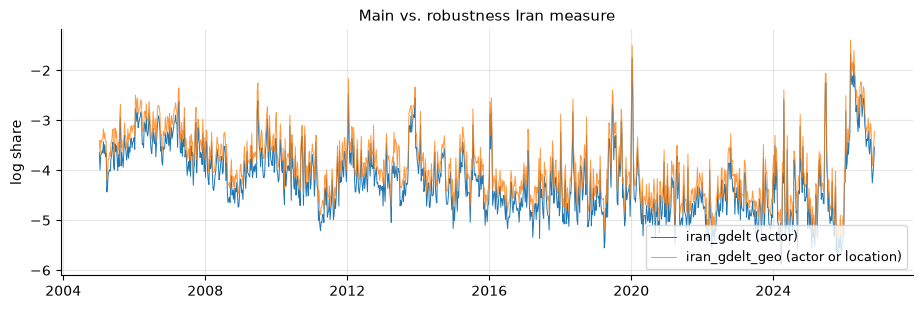

correlation main vs geo: 0.996


In [9]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(panel["date"], panel["iran_gdelt"], lw=0.7, label="iran_gdelt (actor)")
ax.plot(panel["date"], panel["iran_gdelt_geo"], lw=0.7, alpha=0.8, label="iran_gdelt_geo (actor or location)")
ax.set_ylabel("log share"); ax.legend(loc="lower right"); ax.set_title("Main vs. robustness Iran measure")
plots.save_fig(fig, "gdelt_main_vs_geo"); plt.show()
print(f"correlation main vs geo: {panel['iran_gdelt'].corr(panel['iran_gdelt_geo']):.3f}")

There is a very, very high correlation (0.996) between the main and the geo GDELT news about Iran, so we could use either measure.
- Geo sits slightly higher (it counts more articles), but the two move together week by week.
- We keep the main measure in the models and use geo as a robustness check.

### Figure 4: sentiment of the Iran news

- Here we look at the conflict vs cooperation shares in the news and the tone of the Iran news
- Top = share of articles about Iran conflict vs Iran cooperation
- Middle = average tone (negative = hostile wording)
- Bottom: Goldstein measure: -10 is war-like, +10 is cooperative
- The two types of vertical lines: red line = Apr 2013 feed switch, dotted lines = the nine Iran event weeks
- Multicollinearity warning for M3-model: if conflict and cooperation move almost exactly like the main Iran share, a model can't tell them apart

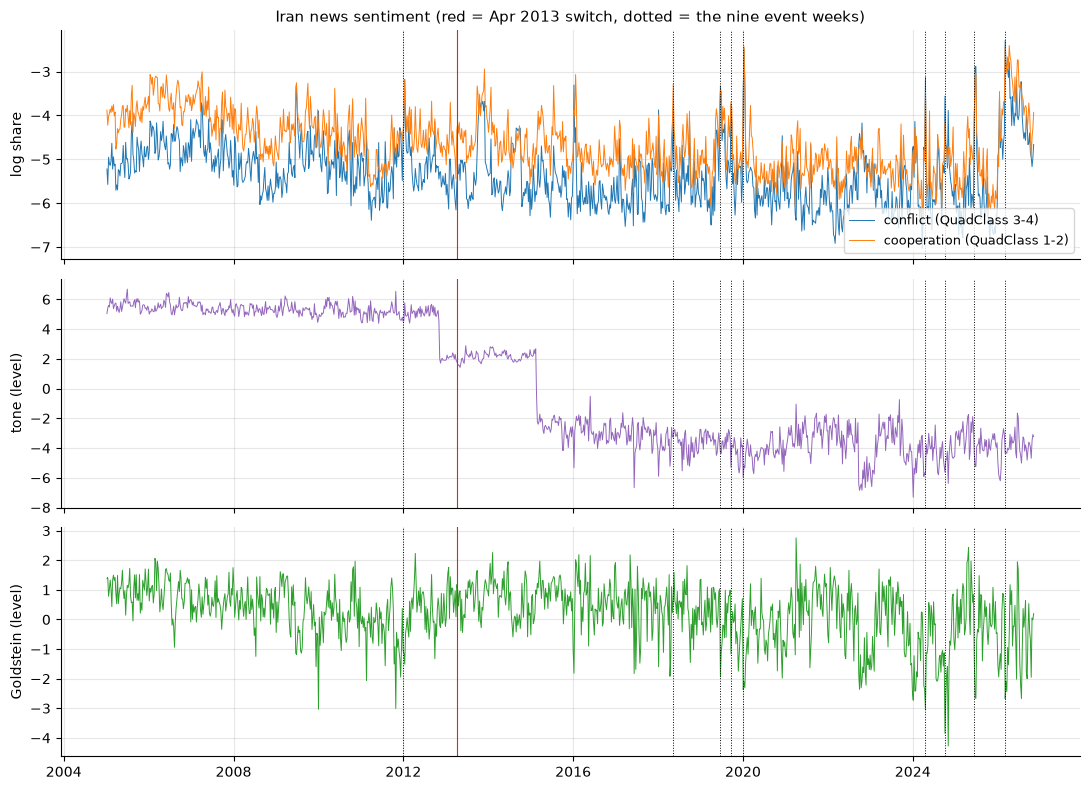

corr(iran_conflict, iran_gdelt) = 0.928; corr(iran_coop, iran_gdelt) = 0.976; corr(iran_conflict, iran_coop) = 0.828


In [10]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(panel["date"], panel["iran_conflict"], lw=0.7, label="conflict (QuadClass 3-4)")
axes[0].plot(panel["date"], panel["iran_coop"], lw=0.7, label="cooperation (QuadClass 1-2)")
axes[0].set_ylabel("log share"); axes[0].legend(loc="lower right")
axes[1].plot(panel["date"], panel["iran_tone"], lw=0.7, color="tab:purple"); axes[1].set_ylabel("tone (level)")
axes[2].plot(panel["date"], panel["iran_goldstein"], lw=0.7, color="tab:green"); axes[2].set_ylabel("Goldstein (level)")
for ax in axes:
    ax.axvline(SWITCH_WEEK, color="tab:red", lw=0.8)          
    for wk in EVENT_WEEKS.values():
        ax.axvline(wk, color="k", ls=":", lw=0.7)                  
axes[0].set_title("Iran news sentiment (red = Apr 2013 switch, dotted = the nine event weeks)")
fig.tight_layout(); plots.save_fig(fig, "gdelt_tone"); plt.show()
print(f"corr(iran_conflict, iran_gdelt) = {panel['iran_conflict'].corr(panel['iran_gdelt']):.3f}; "
      f"corr(iran_coop, iran_gdelt) = {panel['iran_coop'].corr(panel['iran_gdelt']):.3f}; "
      f"corr(iran_conflict, iran_coop) = {panel['iran_conflict'].corr(panel['iran_coop']):.3f}")

Extra insights from this:

- Very high correlation of Iran conflict (0.93) and Iran cooperation (0.98) with the main Iran share: they mostly measure *how much* Iran is in the news, not the direction. In M3 they will be hard to tell apart from `iran_gdelt` (multicollinearity). We deal with that in notebook 03.
- Conflict and cooperation also correlate highly with each other (0.83), but less than with the main share.
- Tone drops in two permanent steps (Nov 2012: about 5 → 2; Feb 2015: about 2.5 → −2.5) and is flat in between. Real sentiment doesn't move like that: these are almost certainly GDELT processing changes (GDELT 2.0 launched in Feb 2015). This is why tone fails the ADF test.
- Goldstein has no such steps and dips clearly in the event weeks (Apr 2024, Oct 2024, Jun 2025, Mar 2026). It is the cleaner sentiment measure.

## 5 · Hourly vs. daily RV

`rv_hourly` (Dukascopy, ~105 hourly returns per week) is the main evaluation target; `rv` (5 daily FRED returns) is the secondary one. They should move together. Their **levels** can differ: the hourly series is a CFD on Brent futures, the daily one is spot. **Nothing is rescaled**: each forecast is scored against each measure as it is. If the ratio of means is outside `RV_LEVEL_RATIO_BAND` = [0.8, 1.25] we flag it.

In [11]:
# ── HOURLY vs DAILY RV: do the two volatility measures agree? 
pi = panel.set_index("date")                                   # same table, indexed by date for slicing
# Three windows: the scaling window (first 2 clean years), the rest of the validation period, and 2019+.
WINDOWS = {"scaling window (first 2 clean years)": C.STANDARDIZE_WINDOW_HOURLY,
           "info: Jun 2013 - Dec 2018": (C.HOURLY_SAMPLE_START, "2018-12-28"),
           "info: 2019 - 2026": ("2019-01-04", C.FREEZE_DATE)}
rows = []
for name, (a, b) in WINDOWS.items():
    w = pi.loc[a:b]
    rows.append({"window": name, "from": a, "to": b, "weeks": int(w["rv_hourly"].notna().sum()),
                 # Do high-volatility weeks line up in both measures? (levels and logs)
                 "corr_levels": w["rv_hourly"].corr(w["rv"]), "corr_logs": w["log_rv_hourly"].corr(w["log_rv"]),
                 # Are they on the same level? 1.0 = same average size; 0.6 = hourly is 40% lower.
                 "ratio_mean_hourly_to_daily": w["rv_hourly"].mean() / w["rv"].mean()})
rv_check = pd.DataFrame(rows)
paths.save_table(rv_check.round(4), "rv_measures_check")      # -> results/tables/rv_measures_check.csv
display(rv_check.round(3))
ratio = rv_check.loc[0, "ratio_mean_hourly_to_daily"]
lo, hi = C.RV_LEVEL_RATIO_BAND                                 # (0.8, 1.25): "close enough" band
print(f"scaling-window ratio {ratio:.3f}: {'inside' if lo <= ratio <= hi else 'OUTSIDE -> tell the team'} [{lo}, {hi}]")

,window,from,to,weeks,corr_levels,corr_logs,ratio_mean_hourly_to_daily
0,scaling window (first 2 clean years),2013-06-07,2015-06-05,105,0.705,0.792,1.153
1,info: Jun 2013 - Dec 2018,2013-06-07,2018-12-28,291,0.701,0.778,0.940
2,info: 2019 - 2026,2019-01-04,2026-11-06,410,0.625,0.791,0.612


scaling-window ratio 1.153: inside [0.8, 1.25]


Insights:

- `corr_levels` / `corr_logs`: do high-volatility weeks line up in both measures? Yes, fairly well: 0.63–0.71 in levels and 0.78–0.79 in logs, in every window.
- `ratio_mean_hourly_to_daily`: in the first 2 clean years the hourly measure is 15.3% *higher* than the daily one (1.153); in 2013–2018 it is 6% lower (0.940). Both are inside [0.8, 1.25].
- 2019–2026 (0.612) looks like a big gap, but it comes from five weeks in Mar–Apr 2020, when the physical spot price (FRED) crashed far harder than futures (week ending Apr 24, 2020: daily rv 6,115 vs. hourly 723). Those 5 weeks are 42% of all daily RV since 2019. Without them the ratio is 0.86, and the median weekly ratio is 1.00. So there is no general level problem.
- We do **not** rescale one measure to the other: each forecast is scored against each measure as it is. Separately, when hourly variables are used *inside* a model (as z-scores), their mean and sd come only from the scaling window, so there is no lookahead bias.

### Figure + Lists: hourly vs daily RV, thin weeks, removed returns

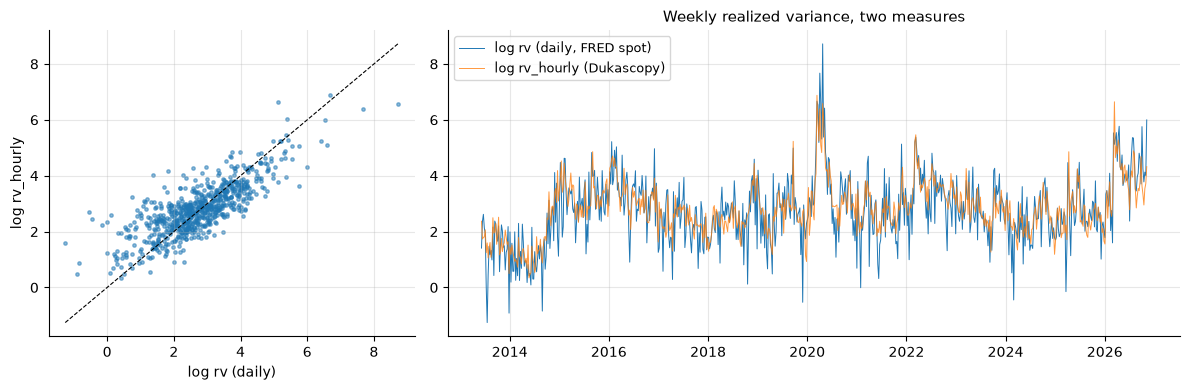

weeks from 2013-06-07 with fewer than 60 hourly returns: 1


,n_hours_week,rv_hourly,rv
date,,,
2013-10-18,58.0,3.212102,1.758515


removed data-hole returns: 9, of which in weeks from 2013-06-07: 1
mean rv_gk/rv_hourly: weeks with a removal 2.033, others 1.023


In [12]:
# ── FIGURE + LISTS: hourly vs daily RV, thin weeks, removed returns ────────────────────

h = pi.loc[C.HOURLY_SAMPLE_START:]                             # only weeks that have hourly RV
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})

# Left: each dot is one week. Dots on the dashed 45-degree line = both measures agree exactly.
a1.scatter(h["log_rv"], h["log_rv_hourly"], s=6, alpha=0.5)
lims = [min(h["log_rv"].min(), h["log_rv_hourly"].min()), max(h["log_rv"].max(), h["log_rv_hourly"].max())]
a1.plot(lims, lims, color="k", lw=0.8, ls="--"); a1.set_xlabel("log rv (daily)"); a1.set_ylabel("log rv_hourly")

# Right: both measures over time.
a2.plot(h.index, h["log_rv"], lw=0.7, label="log rv (daily, FRED spot)")
a2.plot(h.index, h["log_rv_hourly"], lw=0.7, alpha=0.8, label="log rv_hourly (Dukascopy)")
a2.legend(loc="upper left"); a2.set_title("Weekly realized variance, two measures")
fig.tight_layout(); plots.save_fig(fig, "rv_hourly_vs_daily"); plt.show()

# Weeks with few hourly returns (flagged, kept) and weeks with a removed data-hole return.
few = h[h["n_hours_week"] < C.MIN_HOURS_WEEK]                  # normal week ~105; fewer than 60 is unusual
print(f"weeks from {C.HOURLY_SAMPLE_START} with fewer than {C.MIN_HOURS_WEEK} hourly returns: {len(few)}")
if len(few):
    display(few[["n_hours_week", "rv_hourly", "rv"]])

# The returns notebook 01 removed because they spanned a hole in the data: which weeks do they fall in?
removed = S.load_raw("brent_intraday_removed") if (paths.RAW / "brent_intraday_removed.csv").exists() else None
if removed is not None:
    rw = pd.DatetimeIndex(W.week_ending(removed["date"]))
    in_sample = rw[rw >= pd.Timestamp(C.HOURLY_SAMPLE_START)]
    print(f"removed data-hole returns: {len(removed)}, of which in weeks from {C.HOURLY_SAMPLE_START}: {len(in_sample)}")
    # Garman-Klass RV vs hourly RV: in a week where a return was removed, GK (which still sees the full
    # price range) is expected to be higher than hourly RV.
    ratio_gk = h["rv_gk"] / h["rv_hourly"]
    if len(in_sample):
        print(f"mean rv_gk/rv_hourly: weeks with a removal {ratio_gk[ratio_gk.index.isin(in_sample)].mean():.3f}, "
              f"others {ratio_gk[~ratio_gk.index.isin(in_sample)].mean():.3f}")
    else:
        print(f"mean rv_gk/rv_hourly over all hourly weeks: {ratio_gk.mean():.3f}")

**Hourly vs. daily RV:**
- Scatter: the points lie around the 45° line, so the two measures agree on size. The daily one is noisier (only 5 returns a week), especially in calm weeks (left side).
- Time plot: both rise and fall together (2014–16 oil crash, 2020, 2026); the daily one has the more extreme spikes.
- Thin weeks: only 1 week has fewer than 60 hourly returns (Oct 18, 2013: 58). Fine.
- Removed data-hole returns: 9, but only 1 falls in the hourly sample (from Jun 2013). In that week `rv_gk` is 2× `rv_hourly` (other weeks: 1.02×), as expected: Garman–Klass still sees the price move across the hole, hourly RV no longer does.
- Conclusion: `rv_hourly` is a sound main target; we report results on `rv` too.

## 6 · Coverage (listed, never filled)

In [13]:
# Weeks with fewer than 6 of 7 GDELT days (a normal week has 7).
short_g = panel[panel["gdelt_days"] < 6][["date", "gdelt_days", "gdelt_filled", "iran_share"]]
print(f"weeks with fewer than 6 GDELT days: {len(short_g)}"); display(short_g)

# Weeks with fewer than 4 Brent trading days (holiday weeks; also some FRED gaps in 2005-2006).
short_b = panel[panel["n_days"] < 4][["date", "n_days"]]
print(f"weeks with fewer than 4 Brent trading days: {len(short_b)} (holidays): "
      f"{', '.join(short_b['date'].dt.strftime('%Y-%m-%d'))}")

# Weeks where GPR or VIX is missing; a missing value in the 2026 holdout would matter most.
nan_ctrl = panel[panel[["gpr", "vix"]].isna().any(axis=1)][["date", "gpr", "vix"]]
print(f"weeks with missing GPR or VIX: {len(nan_ctrl)}; in the 2026 holdout: "
      f"{int((nan_ctrl['date'] >= '2026-01-01').sum())}")
if len(nan_ctrl):
    display(nan_ctrl)

weeks with fewer than 6 GDELT days: 7


,date,gdelt_days,gdelt_filled,iran_share
472,2014-01-24,5,0,0.045589
660,2017-09-01,5,0,0.007304
693,2018-04-20,5,0,0.011411
844,2021-03-12,5,0,0.014726
1067,2025-06-20,1,0,0.105466
1068,2025-06-27,0,1,0.105466
1069,2025-07-04,3,0,0.020735


weeks with fewer than 4 Brent trading days: 32 (holidays): 2005-03-11, 2005-03-18, 2005-04-01, 2005-04-15, 2005-04-22, 2005-04-29, 2005-05-06, 2005-06-17, 2006-01-13, 2006-03-03, 2006-03-10, 2006-03-17, 2006-03-24, 2006-03-31, 2006-04-07, 2006-04-14, 2006-05-12, 2006-12-29, 2007-02-09, 2007-12-28, 2011-04-29, 2011-12-30, 2012-04-06, 2016-12-30, 2017-12-29, 2018-12-28, 2019-01-04, 2021-12-31, 2022-12-30, 2023-12-29, 2024-12-27, 2025-12-26
weeks with missing GPR or VIX: 0; in the 2026 holdout: 0


## 7 · Checks

In [14]:
# ── CHECKS: each "assert" stops the notebook with a message if something is wrong ──────
p = panel
d = pd.DatetimeIndex(p["date"])
# 1,140 Fridays from Jan 7, 2005 to Nov 6, 2026.
assert len(p) == 1140 and d[0] == pd.Timestamp("2005-01-07") and d[-1] == pd.Timestamp("2026-11-06")
assert (d.day_of_week == 4).all(), "not all Fridays"          # 4 = Friday (Monday = 0)
assert (p["rv"] > 0).all(), p.loc[p["rv"] <= 0, ["date", "rv"]]
assert p["n_days"].between(1, 5).all(), p.loc[~p["n_days"].between(1, 5), ["date", "n_days"]]
# Every Iran-news column must be a real number in every week (no NaN, no infinity from log(0)).
for col in ["iran_gdelt", "iran_gdelt_geo", "iran_conflict", "iran_coop", "iran_tone", "iran_goldstein"]:
    assert np.isfinite(p[col]).all(), (col, p.loc[~np.isfinite(p[col]), "date"])

# Hourly RV: NaN before the start, finite and > 0 from it on, first non-NaN week = the start.
start = pd.Timestamp(C.HOURLY_SAMPLE_START)
assert p.loc[d < start, "rv_hourly"].isna().all()
assert (p.loc[d >= start, "rv_hourly"] > 0).all() and np.isfinite(p.loc[d >= start, "log_rv_hourly"]).all()
assert d[p["rv_hourly"].notna().to_numpy()][0] == start

# Window counts (train / validation / test / holdout).
for (a, b), n in [(C.TRAIN, 417), (C.VALID, 313), (C.TEST, 365), (C.HOLDOUT, 45)]:
    assert ((d >= a) & (d <= b)).sum() == n, (a, b)

# Event weeks and the single carried-forward GDELT week.
assert EVENT_WEEKS["abqaiq_2019"] == pd.Timestamp("2019-09-20") and EVENT_WEEKS["hormuz_2026"] == pd.Timestamp("2026-03-06")
assert p.loc[p["gdelt_filled"] == 1, "date"].tolist() == [pd.Timestamp("2025-06-27")]

paths.check_budget()                                           # repo size limits (data, results, notebooks)
print("all checks passed; size budget OK")

all checks passed; size budget OK


**Before committing:** restart and run all. `weekly_panel.csv`, the two tables and the five figures are committed with this notebook.